# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [1]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [2]:
# 데이터 로드
data = pd.read_csv("abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [3]:
# 필요한 모듈 불러오기
from sklearn.model_selection import train_test_split

In [4]:
# train과 test set 분리 (train:test = 7:3 비율로)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [5]:
#필요한 모듈 불러오기
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [6]:
#릿지모델 생성 및 훈련
ridge = Ridge(alpha=0.3)
ridge.fit(X_train, y_train)

#예측값 구하기
ridge_pred = ridge.predict(X_test)
pred_age = ridge_pred + 1.5

#MSE와 RMSE구하기
age = y_test + 1.5

ridge_mse = mean_squared_error(age, pred_age)
ridge_rmse = np.sqrt(ridge_mse)

print(f'MSE: {ridge_mse:.4f}')
print(f'RMSE: {ridge_rmse:.4f}')

MSE: 5.1573
RMSE: 2.2710


3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [7]:
data.columns

coef = pd.Series(data=ridge.coef_, index=data.columns)
print(coef.sort_values(ascending=False))

Shell weight      10.098531
Diameter           8.165539
Whole weight       7.732939
Height             7.311134
Length             2.005972
M                  0.363392
F                  0.232348
I                 -0.595740
Viscera weight    -7.942734
Shucked weight   -18.655656
dtype: float64


* Height과 Shell weight 등이 큰 (+) 회귀 계수를 가지므로 높이가 크고 껍질이 무거울수록 전복의 나이가 많다고 예측하는 경향이 큼
* Shunked weight나 Viscera weight 등은 회귀 계수가 음(-)이여서, 해당 값이 클수록 나이가 어리게 예측됨

3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [8]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [9]:
#alphas list 값을 반복하면서 alpha에 따른 평균 rmse를 구함
for alpha in alphas:
    ridge = Ridge(alpha=alpha)

    #cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산
    neg_mse_scores = cross_val_score(ridge, X_train, y_train, scoring="neg_mean_squared_error", cv=5)
    rmse=np.sqrt(-1*neg_mse_scores)
    avg_rmse = np.mean(rmse)
    print( 'alpha {0} 일 때 5 folds의 평균 RMSE: {1:.3f}'. format(alpha, avg_rmse))

alpha 0 일 때 5 folds의 평균 RMSE: 2.189
alpha 0.1 일 때 5 folds의 평균 RMSE: 2.183
alpha 1 일 때 5 folds의 평균 RMSE: 2.181
alpha 10 일 때 5 folds의 평균 RMSE: 2.319
alpha 100 일 때 5 folds의 평균 RMSE: 2.567


## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [10]:
# 필요한 모듈 임포트
from xgboost import XGBRegressor

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [11]:
#모델 생성 및 훈련
xgb_reg = XGBRegressor()
xgb_reg.fit(X_train, y_train)

#예측값 구하기
xgb_pred = xgb_reg.predict(X_test)
xgb_pred_age = xgb_pred + 1.5

#MSE와 RMSE 구하기
test_age = y_test + 1.5

xgb_mse = mean_squared_error(test_age, xgb_pred_age)
xgb_rmse = np.sqrt(xgb_mse)

print('MSE:{0:.3f}, RMSE:{1:.3f}'.format(xgb_mse, xgb_rmse))

MSE:5.750, RMSE:2.398


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

<Axes: xlabel='None', ylabel='None'>

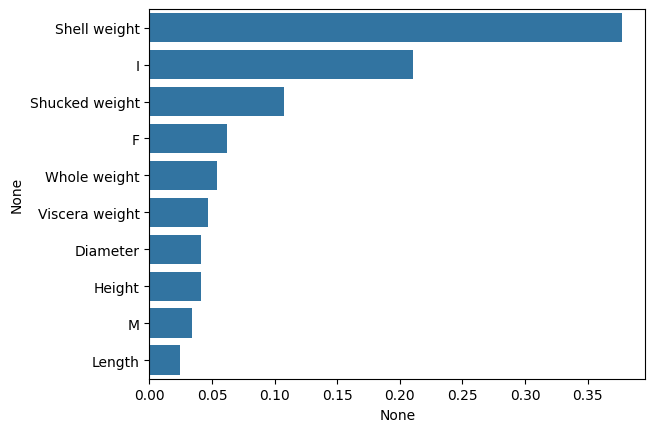

In [12]:
import seaborn as sns
%matplotlib inline

feature_series=pd.Series(data=xgb_reg.feature_importances_, index=data.columns)
feature_series=feature_series.sort_values(ascending=False)
sns.barplot(x=feature_series, y=feature_series.index)

---

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [13]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [14]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [15]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [16]:
model = LogisticRegression(multi_class='multinomial')
model.fit(x_train, y_train)

LogisticRegression(multi_class='multinomial')

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [17]:
#기울기
model.coef_

array([[-1.99751338e-01,  3.65451144e-01,  1.49472353e-01,
        -1.88027194e-01, -2.28494592e-02,  1.95456785e-01,
         4.66701970e-01, -1.66796877e-02,  8.23898405e-02,
         6.75013134e-02, -1.92622072e-02,  2.94916201e-01,
         7.42522347e-03],
       [ 5.96476523e-01, -7.88673910e-01, -1.26181652e-01,
         2.12254429e-01, -1.13504086e-02,  3.15786394e-01,
         3.55148523e-01,  3.34675938e-02,  2.79036084e-01,
        -1.17202662e+00,  2.61166065e-01,  4.64732238e-01,
        -8.33633769e-03],
       [-3.96725185e-01,  4.23222765e-01, -2.32907005e-02,
        -2.42272356e-02,  3.41998678e-02, -5.11243179e-01,
        -8.21850494e-01, -1.67879061e-02, -3.61425924e-01,
         1.10452531e+00, -2.41903857e-01, -7.59648438e-01,
         9.11114220e-04]])

In [18]:
#절편
model.intercept_

array([-0.04177842,  0.09551058, -0.05373216])

3-3) 모델의 정확도를 구하세요.

In [19]:
#모델의 예측값 구하기
y_pred = model.predict(x_test)

#모델의 정확도 구하기
accuracy = metrics.accuracy_score(y_test, y_pred)
print(accuracy)

0.9629629629629629
